# Limpieza y Preprocesamiento

# Objetivo: analizar si las características comerciales de los productos de Falabella determinan el precio final del producto

# Nota:
En la Entrega 1 del proyecto se realizó la limpieza inicial de los datos obtenidos tras el web scraping de Falabella Perú. A continuación, se detallan los pasos metodológicos que permitieron depurar el dataset bruto (falabella_productos.csv) y estructurarlo para su posterior análisis.

# Data Cleaning I

Para este proyecto se realizará la estandarización de la estructura tabular, asegurando que los nombres de las columnas sean limpios, intuitivos y sin caracteres especiales, y estableciendo un índice único o compuesto adecuado para la identificación de cada registro.

Objetivo: Garantizar la integridad estructural del dataset crudo obtenido mediante web scraping, eliminando redundancias y estandarizando los identificadores de las variables.

Incluye:
- Eliminación de duplicados exactos: Para evitar sesgos en el conteo de más de 1,000 registros.
- Estandarización de nombres de columnas: Conversión de etiquetas a minúsculas, eliminación de espacios en blanco y sustitución de caracteres especiales o tildes por guiones bajos (ej. Precio Normal (S/.) $\rightarrow$ precio_normal), facilitando la manipulación en Pandas.
- Inspección inicial de dimensiones: Reporte formal del número inicial de filas y columnas recolectadas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 1. Carga del dataset
df_raw = pd.read_csv("../data/dataset_inicial.csv")
print(f"Registros cargados: {len(df_raw)}")

# 2. Eliminación de registros duplicados
df_clean = df_raw.drop_duplicates().copy()
print(f"Registros tras eliminar duplicados: {len(df_clean)}")
# Estandarización de nombres de columnas
df_clean.columns = (
    df_clean.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("[^a-zA-Z0-9_]", "", regex=True)
)
print(df_clean.keys())
print(df_clean.shape)

Registros cargados: 1830
Registros tras eliminar duplicados: 1830
Index(['marca', 'nombre', 'vendedor', 'precio', 'precio_original', 'descuento',
       'calificacion', 'cantidad_resenas', 'calificacion_con_resenas'],
      dtype='object')
(1830, 9)


- Como se puede observar, la cantidad eliminada de duplicados es 266 registros, dejando a la cantidad de registros con 1834 productos.

- Los nombres de las columnas se encuentran estandarizadas de forma convencional tal que sus nombres están en minúscula y sin espacios.

# Data Cleaning II: Restructuración y Formato

Ahora, se realizará la reestructuración y reformulación de la tabla, lo que incluye la selección de variables relevantes, conversión de tipos de datos (numéricos, categóricos o fechas) y la creación de características derivadas necesarias para el análisis.


Objetivo: Convertir los datos de tipo texto (string) extraídos de la web a sus tipos de datos correctos (numéricos, enteros o categóricos) para permitir operaciones estadísticas y matemáticas.

Incluye:

- Limpieza de precios y ofertas: Eliminación de símbolos de moneda (S/.), separadores de miles (comas) y símbolos de porcentaje (%) en columnas clave como precio, precio_original y descuento, transformándolas a datos de punto flotante (float).

- Conversión de reseñas y calificaciones: Limpieza de caracteres no numéricos en la cantidad de reseñas para convertirlas a enteros (int), y aseguramiento de que las calificaciones y puntuaciones tengan formato numérico estándar.


In [3]:
# 3. Funcion para la limpieza y conversion
def limpiar_a_numero(val):
    if pd.isna(val) or val is None:
        return np.nan

    val_str = str(val).replace(",", "").strip()

    # MANTENEMOS EL GUION '-' PARA RECONOCER SEPARACIONES DE RANGOS
    caracteres_filtrados = []
    for char in val_str:
        if char.isdigit() or char == '.' or char == '-':
            caracteres_filtrados.append(char)
        else:
            caracteres_filtrados.append(' ') # Reemplaza texto por espacios

    texto_limpio = "".join(caracteres_filtrados)

    # SEPARAMOS CADA PRECIO ENCONTRADO EN UNA LISTA
    numeros = []
    for parte in texto_limpio.split():
        p = parte.replace('-', '').strip()
        if p:
            try:
                num = float(p)
                numeros.append(num)
            except ValueError:
                continue

    if len(numeros) == 0:
        return np.nan
    else:
        # Devuelve el mayor de los precios detectados (evita tomar cuotas mensuales bajas)
        return max(numeros)

# Aplicar la función a las columnas de precios
df_clean['precio'] = df_clean['precio'].apply(limpiar_a_numero)
df_clean['precio_original'] = df_clean['precio_original'].apply(limpiar_a_numero)

# CONVERSIÓN Y CÁLCULO DEL DESCUENTO
df_clean['descuento'] = np.where(
    df_clean['precio_original'] > 0,
    ((df_clean['precio_original'] - df_clean['precio']) / df_clean['precio_original']) * 100,
    0.0
)
df_clean['descuento'] = df_clean['descuento'].round(2)

# ESTANDARIZACIÓN DE OTROS ATRIBUTOS: categórico a numérico
df_clean['calificacion'] = pd.to_numeric(df_clean['calificacion'], errors='coerce')
df_clean['cantidad_resenas'] = pd.to_numeric(df_clean['cantidad_resenas'], errors='coerce').fillna(0).astype(int)

En cuanto a la calificacion, se convirtió a una variable de tipo float, porque esta admite valoraciones como 3.5, 4.2, etc. En cambio, cantidad_resenas, indica cuántas personas han emitido una opinión sobre el producto, es decir, un valor entero.

Reporte del dataset con los cambios realizados

In [4]:
print(
    '---TIPOS DE DATOS Y ESTRUCTURA TRAS REESTRUCTURACIÓN DE FORMATO---\n'
)
df_clean.info()
print('\nPrimeras filas con los tipos de datos ya corregidos:')
display(df_clean.head())

---TIPOS DE DATOS Y ESTRUCTURA TRAS REESTRUCTURACIÓN DE FORMATO---

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1830 entries, 0 to 1829
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   marca                     1830 non-null   object 
 1   nombre                    1830 non-null   object 
 2   vendedor                  1830 non-null   object 
 3   precio                    1830 non-null   float64
 4   precio_original           1830 non-null   float64
 5   descuento                 1830 non-null   float64
 6   calificacion              1830 non-null   float64
 7   cantidad_resenas          1830 non-null   int64  
 8   calificacion_con_resenas  897 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 128.8+ KB

Primeras filas con los tipos de datos ya corregidos:


,marca,nombre,vendedor,precio,precio_original,descuento,calificacion,cantidad_resenas,calificacion_con_resenas
0,APPLE,IPhone 14 128GB Morado Reacondicionado A2649,Por Electronic Deals Pe,1469.0,1999.0,26.51,4.2500,4,4.2500
1,XIAOMI,Batería externa Power Bank 20000mAh Integrated...,Por Xiaomi Tienda Oficial,79.0,89.0,11.24,4.7273,22,4.7273
2,APPLE,IPhone 18 Pro Max 256GB,Por Falabella,6999.0,7299.0,4.11,0.0000,0,NaN
3,APPLE,IPhone 18 Pro 256GB,Por Falabella,6499.0,6699.0,2.99,0.0000,0,NaN
4,SAMSUNG,Celular Galaxy A57 5G,Por Falabella,1899.0,2299.0,17.40,4.7115,52,4.7115


En esta etapa se realizó la reestructuración y reformulación de los tipos de datos. Se transformaron las variables monetarias (precio y precio_original) eliminando símbolos e inconsistencias de texto mediante funciones de conversión numérica, se calculó el porcentaje de descuento real como característica derivada, y se estandarizaron las calificaciones y reseñas para garantizar que el dataset quede listo para el análisis exploratorio y estadístico.

# Missing Values
A continuación se realizará un diagnóstico exhaustivo de los valores nulos para identificar su mecanismo (MCAR, MAR o MNAR) mediante conteos y análisis de distribución, aplicando posteriormente la estrategia de imputación o eliminación adecuada según el impacto en la variable objetivo.

Objetivo: Evaluar y controlar la calidad de la información asegurando que la pérdida de datos esté dentro de los límites aceptables establecidos en la metodología del proyecto (menor al 10% por columna clave).

Incluye:
- Diagnóstico cuantitativo: Cálculo de la cantidad absoluta y el porcentaje de valores nulos (NaN) por cada variable del dataset mediante reportes tabulares y mapas de calor.
- Validación de umbrales: Verificación formal de que los atributos críticos (como precio, marca y vendedor) cumplan rigurosamente con la regla de no superar el 10% de valores faltantes.
- Tratamiento: Eliminación de registros donde falte la variable objetivo (precio) o la imputación justificada para variables secundarias.

In [5]:
print("__Reporte de los Valores Nulos__")
nulos_conteo = df_clean.isnull().sum()
nulos_porcentaje = (df_clean.isnull().mean() * 100).round(2)

df_nulos = pd.DataFrame(
    {"Valores Nulos": nulos_conteo, "Porcentaje (%)": nulos_porcentaje}
)
display(df_nulos)

__Reporte de los Valores Nulos__


,Valores Nulos,Porcentaje (%)
marca,0,0.00
nombre,0,0.00
vendedor,0,0.00
precio,0,0.00
precio_original,0,0.00
descuento,0,0.00
calificacion,0,0.00
cantidad_resenas,0,0.00
calificacion_con_resenas,933,50.98


Hay nulos en precio_original pero no en la variable 'precio'. La Regla de negocio decía que si el precio_original está vacío, entonces significa que el precio real es el precio actual, es decir el de 'precio'.

In [6]:
# Ninguna columna debe superar el 10% de nulos
print('=== VALIDACIÓN DEL UMBRAL DEL 10% ===')
for col in df_clean.columns:
  pct = (df_clean[col].isnull().sum() / len(df_clean)) * 100
  if pct > 10:
    print(f'La columna {col} supera el umbral con {pct:.2f}%')
  else:
    print(f'(válido) {col}: {pct:.2f}% de nulos (Cumple el umbral < 10%)')

# Tratamiento de nulos en precio_original
df_clean['precio_original'] = df_clean['precio_original'].fillna(
    df_clean['precio']
)

# Recalcular el descuento por si acaso algún precio original fue rellenado
df_clean['descuento'] = np.where(
    df_clean['precio_original'] > 0,
    (
        (df_clean['precio_original'] - df_clean['precio'])
        / df_clean['precio_original']
    )
    * 100,
    0.0,
)
df_clean['descuento'] = df_clean['descuento'].round(2)

print('\n=== NULOS DESPUÉS DEL TRATAMIENTO ===')
print(df_clean.isnull().sum())

=== VALIDACIÓN DEL UMBRAL DEL 10% ===
(válido) marca: 0.00% de nulos (Cumple el umbral < 10%)
(válido) nombre: 0.00% de nulos (Cumple el umbral < 10%)
(válido) vendedor: 0.00% de nulos (Cumple el umbral < 10%)
(válido) precio: 0.00% de nulos (Cumple el umbral < 10%)
(válido) precio_original: 0.00% de nulos (Cumple el umbral < 10%)
(válido) descuento: 0.00% de nulos (Cumple el umbral < 10%)
(válido) calificacion: 0.00% de nulos (Cumple el umbral < 10%)
(válido) cantidad_resenas: 0.00% de nulos (Cumple el umbral < 10%)
La columna calificacion_con_resenas supera el umbral con 50.98%

=== NULOS DESPUÉS DEL TRATAMIENTO ===
marca                         0
nombre                        0
vendedor                      0
precio                        0
precio_original               0
descuento                     0
calificacion                  0
cantidad_resenas              0
calificacion_con_resenas    933
dtype: int64


Tras aplicar el proceso de limpieza y las reglas de negocio sobre los precios, se ejecutó un diagnóstico general de valores nulos. Como se observa en la tabla resultante, el dataset cuenta con un 0% de valores faltantes en todas sus columnas, garantizando la completitud de la información para el análisis exploratorio.

# Outliers

Se utilizará el criterio del rango intercuartílico (IQR) en combinación con el análisis bivariado para depurar errores de parseo web y valores atípicos extremos.

Objetivo: Identificar y mitigar el impacto de valores extremos en los precios o descuentos (por ejemplo, errores de tipeo en el scraping o precios hiperinflados/de cuotas) que puedan distorsionar las correlaciones y modelos.

Con el fin de que las estadísticas descriptivas y el análisis de valores atípicos se calculen sobre datos coherentes, se aplican correcciones previas, incluyendo la eliminación del error de parseo extremo detectado (producto fantasma con precio de 70,000 soles).

In [7]:
# 1. CORRECCIÓN DE ERRORES LÓGICOS Y DE PARSEO WEB
condicion_precio = (df_clean["precio"] > 100000) | (df_clean["precio"] >= 70000)
condicion_precio_original = (df_clean["precio_original"] > 100000) | (df_clean["precio_original"] >= 70000)
condicion_descuento = (df_clean["descuento"] < 0) | (
    df_clean["descuento"] > 100
)
#condicion_accesorios = df_clean["precio"] < 300

df_defectuosos = df_clean[
    condicion_precio | condicion_precio_original | condicion_descuento
]
print(f"Registros defectuosos detectados por errores web: {len(df_defectuosos)}")

# Eliminarlos del dataset principal
df_clean = df_clean[
    ~(condicion_precio | condicion_precio_original | condicion_descuento)
].copy()
print(f"Registros restantes tras la corrección: {len(df_clean)}")

# 2. CREACIÓN DE VARIABLE COMPLEMENTARIA (Calificación con reseñas reales)
df_clean["calificacion_con_resenas"] = df_clean["calificacion"].where(
    (df_clean["calificacion"] >= 1) & (df_clean["calificacion"] <= 5)
)

# Estadísticas descriptivas de control
numericas = [
    "precio",
    "precio_original",
    "descuento",
    "calificacion",
    "calificacion_con_resenas",
    "cantidad_resenas",
]
print("\n--Estadísticas descriptivas--")
display(df_clean[numericas].describe().round(2))

Registros defectuosos detectados por errores web: 0
Registros restantes tras la corrección: 1830

--Estadísticas descriptivas--


,precio,precio_original,descuento,calificacion,calificacion_con_resenas,cantidad_resenas
count,1830.00,1830.00,1830.00,1830.00,897.00,1830.00
mean,336.26,463.05,34.14,2.11,4.31,10.52
std,967.39,1299.73,16.15,2.26,0.99,139.25
min,7.00,7.90,0.00,0.00,1.00,0.00
25%,34.00,54.90,23.33,0.00,4.00,0.00
50%,43.00,69.90,36.38,0.00,4.73,0.00
75%,99.00,149.90,44.62,4.68,5.00,2.00
max,10999.00,11999.00,69.80,5.00,5.00,5189.00


Posteriormente, se implementa la detección cuantitativa de valores atípicos utilizando el criterio del Rango Intercuartílico (IQR). Esto permite dimensionar el volumen de productos que se ubican fuera de los límites superior e inferior tradicionales, identificando la dispersión extrema en variables clave como el precio y el volumen de reseñas.

In [8]:
def detectar_outliers(serie):
  serie_limpia = serie.dropna()
  Q1 = serie_limpia.quantile(0.25)
  Q3 = serie_limpia.quantile(0.75)
  IQR = Q3 - Q1
  limite_inf = Q1 - 1.5 * IQR
  limite_sup = Q3 + 1.5 * IQR
  outliers = serie_limpia[
      (serie_limpia < limite_inf) | (serie_limpia > limite_sup)
  ]
  return len(outliers), limite_inf, limite_sup

variables_outliers = [
    "precio",
    "precio_original",
    "descuento",
    "calificacion_con_resenas",
    "cantidad_resenas",
]

print("\n=== REPORTE DE OUTLIERS (CRITERIO IQR) ===")
for col in variables_outliers:
  n_out, li, ls = detectar_outliers(df_clean[col])
  print(f"{col}: {n_out} outliers detectados (Límites: [{li:.2f}, {ls:.2f}])")


=== REPORTE DE OUTLIERS (CRITERIO IQR) ===
precio: 273 outliers detectados (Límites: [-63.50, 196.50])
precio_original: 287 outliers detectados (Límites: [-87.60, 292.40])
descuento: 0 outliers detectados (Límites: [-8.61, 76.55])
calificacion_con_resenas: 63 outliers detectados (Límites: [2.50, 6.50])
cantidad_resenas: 265 outliers detectados (Límites: [-3.00, 5.00])


# Análisis Univariado

Posteriormente, se realiza el gráfico Univariado mediantes boxplot e histogramas para cada una de las variables numéricas del dataset.

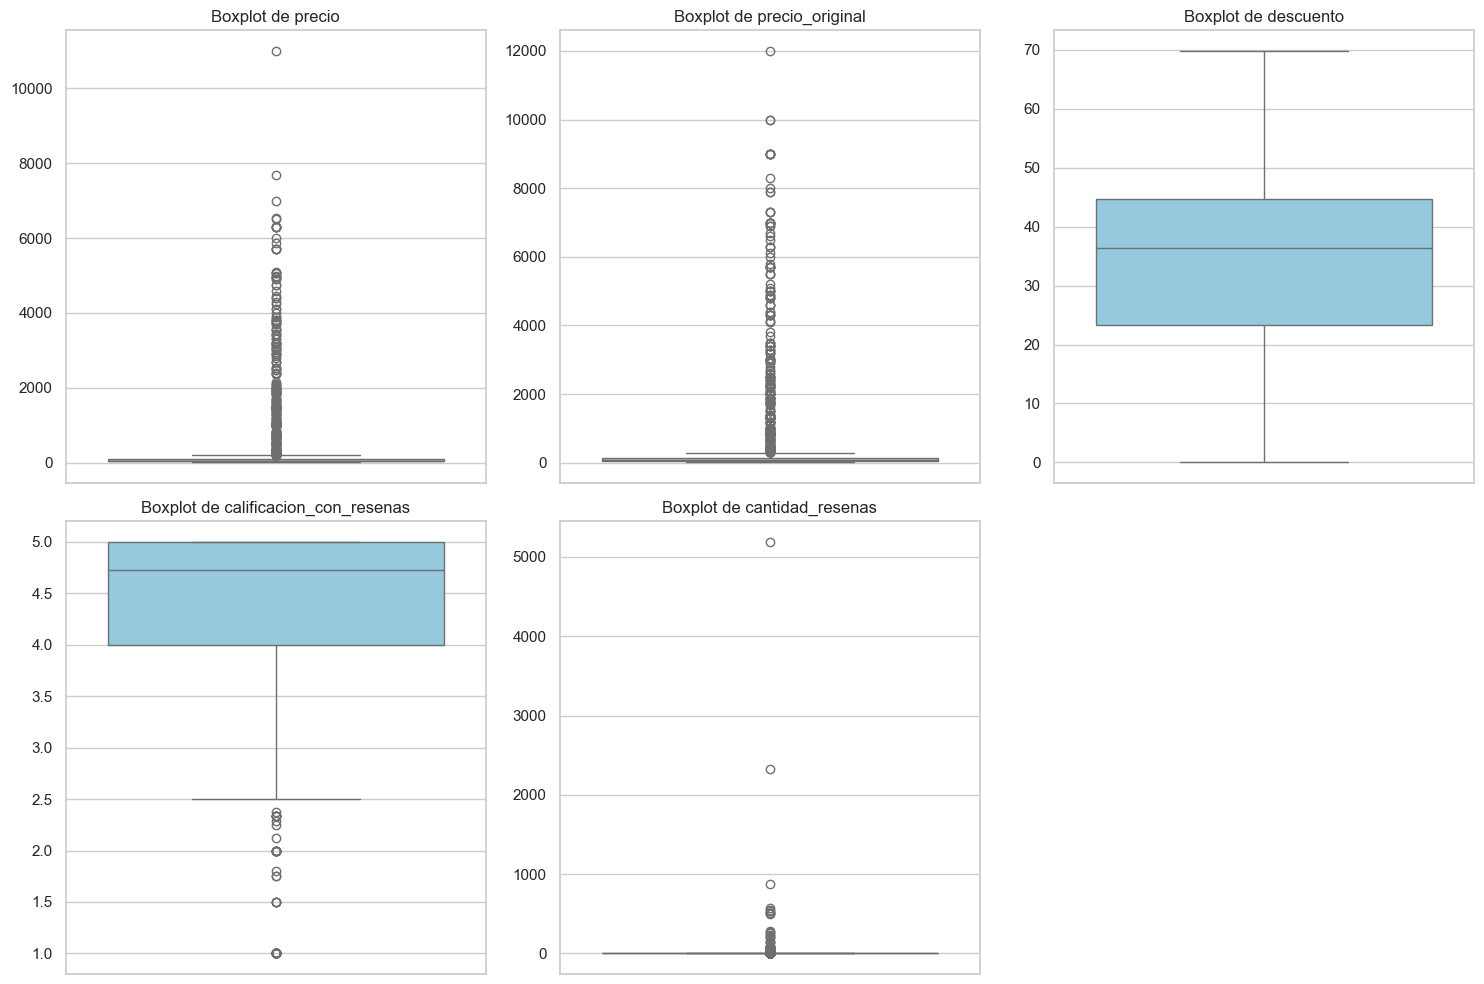

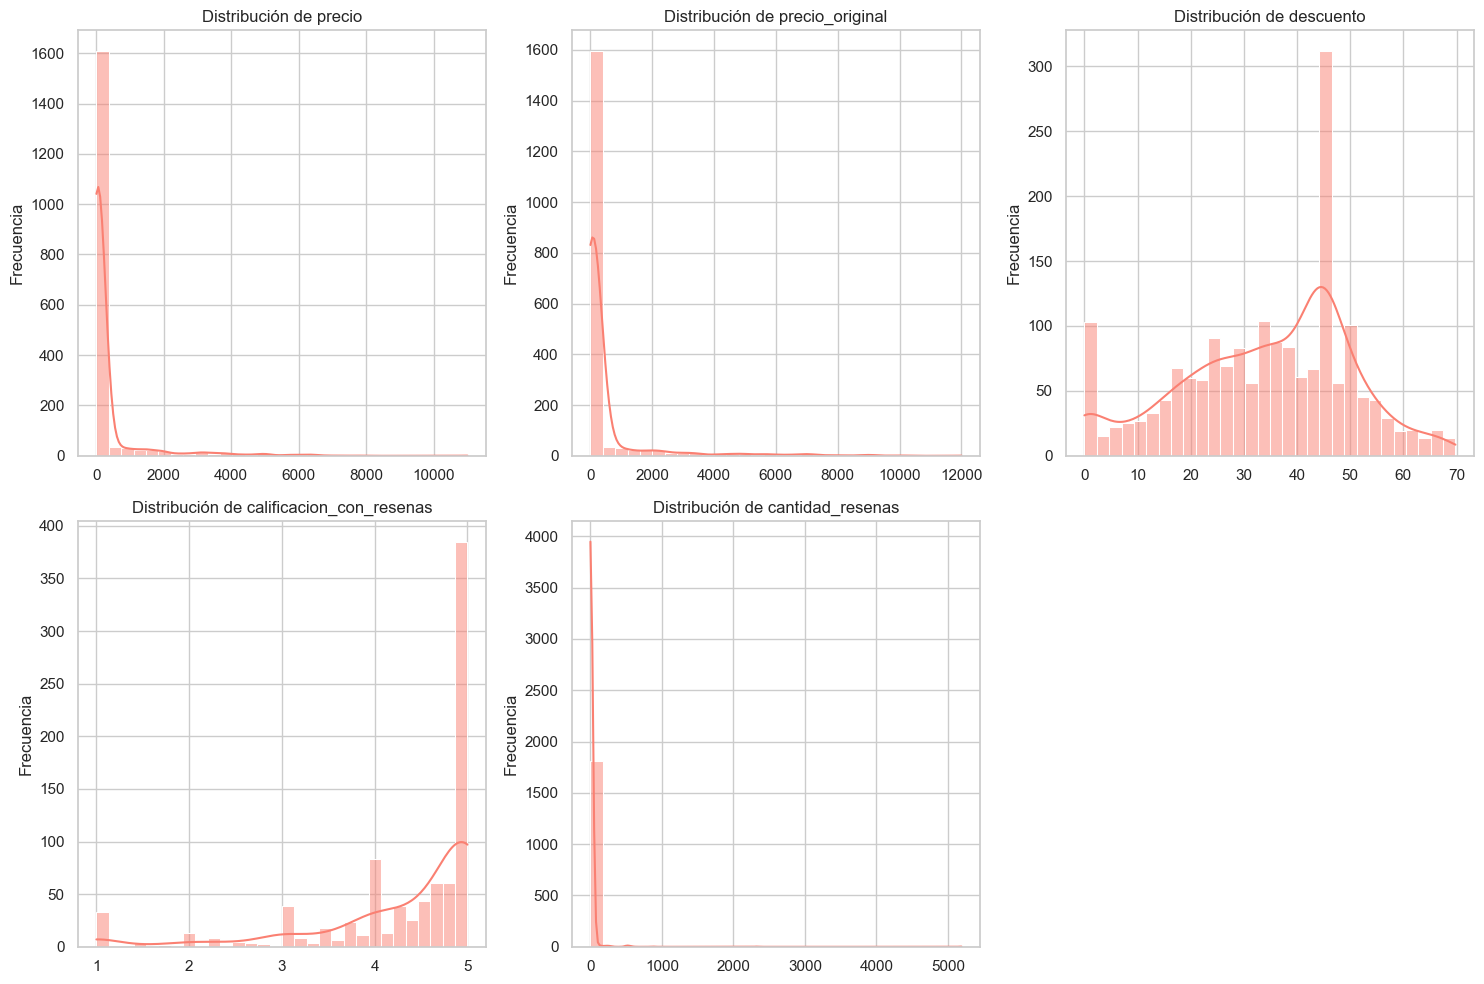

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
variables_grafico = [
    "precio",
    "precio_original",
    "descuento",
    "calificacion_con_resenas",
    "cantidad_resenas",
]

plt.figure(figsize=(15, 10))
for i, col in enumerate(variables_grafico, 1):
  plt.subplot(2, 3, i)
  sns.boxplot(y=df_clean[col], color="skyblue")
  plt.title(f"Boxplot de {col}", fontsize=12)
  plt.ylabel("")

plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 10))
for i, col in enumerate(variables_grafico, 1):
  plt.subplot(2, 3, i)
  sns.histplot(df_clean[col].dropna(), kde=True, color="salmon", bins=30)
  plt.title(f"Distribución de {col}", fontsize=12)
  plt.xlabel("")
  plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

- Distribución de Precios (Univariado): Los histogramas y boxplots muestran una fuerte asimetría positiva (sesgo a la derecha). La gran mayoría de los registros se concentran en precios bajos (reflejando la gran cantidad de accesorios del ecosistema móvil), con una larga cola que representa los smartphones de gama media hasta la ultra-alta (llegando a los 12,000 soles).

- Calificaciones y Descuentos (Univariado): Las notas de los usuarios están fuertemente sesgadas hacia puntajes altos (pico en 5.0), indicando alta satisfacción general en los productos evaluados. Los descuentos tienen una distribución bimodal, concentrándose la mayoría entre el 35% y 45%.

# Análisis Bivariado

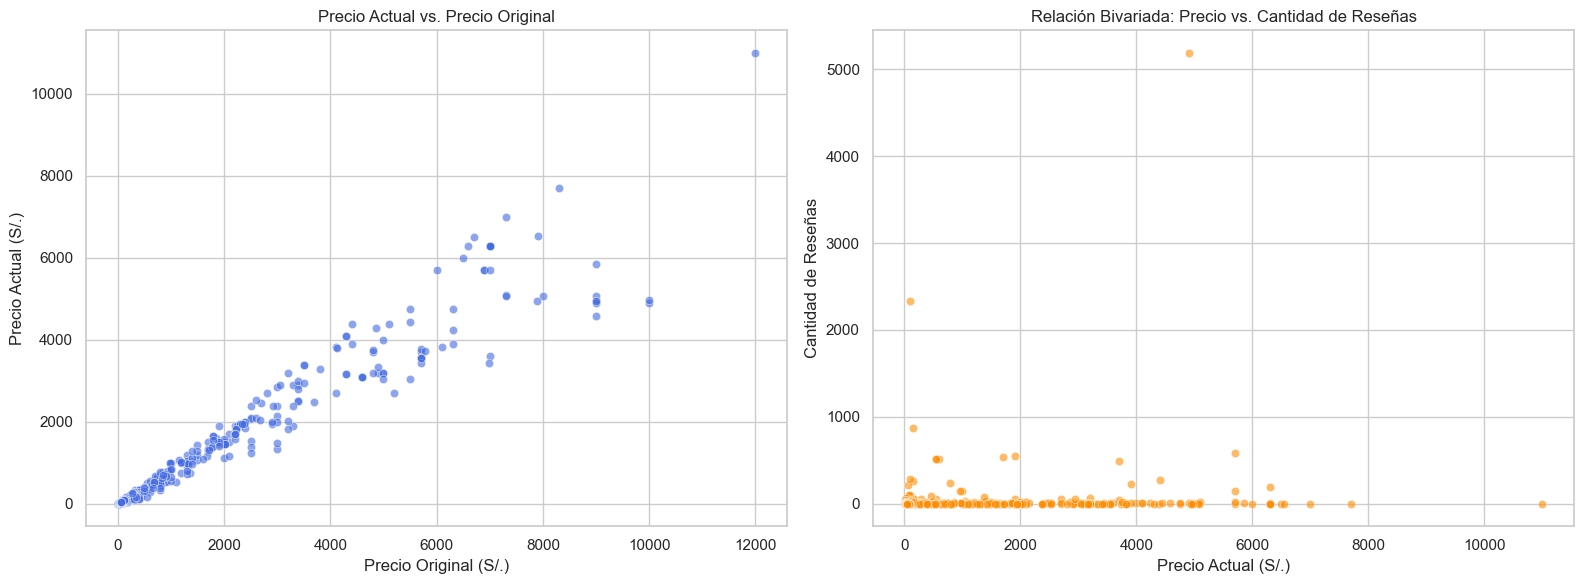

In [10]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(
    data=df_clean,
    x="precio_original",
    y="precio",
    alpha=0.6,
    color="royalblue",
)
plt.title("Precio Actual vs. Precio Original", fontsize=12)
plt.xlabel("Precio Original (S/.)")
plt.ylabel("Precio Actual (S/.)")

plt.subplot(1, 2, 2)
sns.scatterplot(
    data=df_clean,
    x="precio",
    y="cantidad_resenas",
    alpha=0.6,
    color="darkorange",
)
plt.title("Relación Bivariada: Precio vs. Cantidad de Reseñas", fontsize=12)
plt.xlabel("Precio Actual (S/.)")
plt.ylabel("Cantidad de Reseñas")

plt.tight_layout()
plt.show()

- Existe una correlación lineal positiva y lógica entre el Precio Original y el Actual, confirmando que la data limpia ya no contiene errores groseros de scraping.

- La relación "Precio vs. Reseñas" revela que los productos más populares y comentados (algunos con más de 5,000 opiniones) pertenecen exclusivamente a los segmentos de precios bajos y medios. Los equipos premium o muy costosos registran una interacción casi nula (cero o escasas reseñas), lo cual es coherente con su bajo volumen de ventas.

In [11]:
df_clean.shape

(1830, 9)

In [ ]:
# Exportación de dataset final depurado y listo para modelamiento/visualización
df_clean.to_csv('../data/dataset_inicial.csv', index=False, encoding='utf-8-sig')
print("Dataset final exportado exitosamente como 'dataset_inicial.csv'.")

Dataset final exportado exitosamente como 'dataset_inicial.csv'.


In [13]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1830 entries, 0 to 1829
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   marca                     1830 non-null   object 
 1   nombre                    1830 non-null   object 
 2   vendedor                  1830 non-null   object 
 3   precio                    1830 non-null   float64
 4   precio_original           1830 non-null   float64
 5   descuento                 1830 non-null   float64
 6   calificacion              1830 non-null   float64
 7   cantidad_resenas          1830 non-null   int64  
 8   calificacion_con_resenas  897 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 128.8+ KB


In [14]:
df_clean['calificacion_con_resenas'].isnull().sum()

np.int64(933)